# ECG–ICD Association Analysis


=== ORIGINAL DATA ===
ECG observations: 3778
ECG patients: 916
ICD-9 patients: 714

=== ANALYSIS COHORT ===
Retained ECG observations: 2809
Retained patients: 554
Excluded patients: 362

=== SELECTED ICD CODES ===
icd_code
4019     292
2724     213
53081    143
2859     114
41401    113
5849     111
V1582    110
25000    108
311      104
4280     100
42731     95
5990      89
3051      78
40390     72
30000     70
2720      66
V5866     62
2761      61
5859      61
2449      60
Name: subject_id, dtype: int64

=== OUTCOME QUALITY CONTROL ===

avg_t_peak_val
count    2809.000000
mean        0.115990
std         0.102171
min        -0.541083
25%         0.053818
50%         0.106933
75%         0.177222
max         0.639615
Name: avg_t_peak_val, dtype: float64
Most frequent values:
avg_t_peak_val
0.189750    2
0.100200    2
0.094333    2
0.136000    2
0.060625    2
0.149333    2
0.012889    2
0.154556    2
0.060250    2
0.110000    2
Name: count, dtype: int64

SCREENING OUTCOME: avg_t_pe

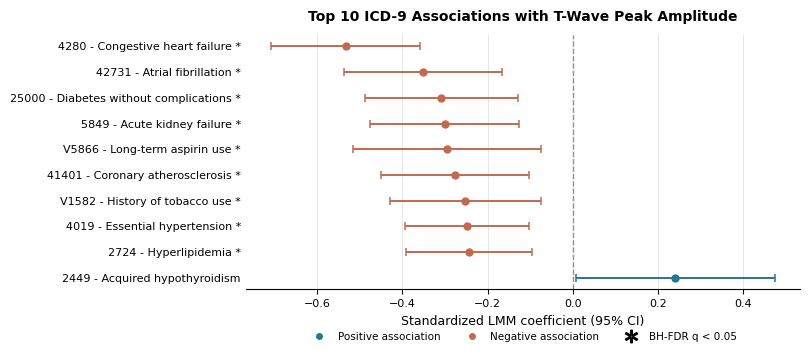


=== FINAL SUMMARY ===

Outcome: avg_t_peak_val
Fitted models: 20
Models without flagged warnings: 20
FDR-significant associations: 9


In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests


# ============================================================
# 1. CONFIGURATION
# ============================================================

DATA_DIR = Path("Data")  # Local credentialed-access files
ICD_PATH = DATA_DIR / "icd_ecg_filtered.csv"
TWAVE_PATH = DATA_DIR / "01_twave_features.csv"

OUTPUT_DIR = Path("icd_screening_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TOP_N = 20
MIN_EXPOSED_PATIENTS = 10
MIN_UNEXPOSED_PATIENTS = 10

OUTCOMES = ["avg_t_peak_val"]


# ============================================================
# 2. LOAD DATA
# ============================================================

twave = pd.read_csv(TWAVE_PATH)

icd = pd.read_csv(
    ICD_PATH,
    dtype={"icd_code": str}
)

required_twave = {
    "subject_id",
    "avg_t_peak_val"
}

required_icd = {
    "subject_id",
    "icd_code",
    "icd_version"
}

for name, df, required in [
    ("T-wave", twave, required_twave),
    ("ICD", icd, required_icd)
]:
    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} missing columns: {sorted(missing)}"
        )

for df in [twave, icd]:
    df["subject_id"] = (
        df["subject_id"].astype("string").str.strip()
    )

for outcome in OUTCOMES:
    twave[outcome] = pd.to_numeric(
        twave[outcome],
        errors="coerce"
    )

    twave.loc[
        ~np.isfinite(twave[outcome]),
        outcome
    ] = np.nan

icd["icd_code"] = (
    icd["icd_code"]
    .astype("string")
    .str.replace(".", "", regex=False)
    .str.upper()
    .str.strip()
)

icd["icd_version"] = pd.to_numeric(
    icd["icd_version"],
    errors="coerce"
)

# ICD-10 to ICD-9 mapping must already be completed. This selects the ICD-9 rows only.
icd = icd.loc[
    (icd["icd_version"] == 9)
    & icd["icd_code"].notna()
    & icd["subject_id"].notna()
].copy()

twave = twave.dropna(subset=["subject_id"]).copy()

print("\n=== ORIGINAL DATA ===")
print("ECG observations:", len(twave))
print("ECG patients:", twave.subject_id.nunique())
print("ICD-9 patients:", icd.subject_id.nunique())


# ============================================================
# 3. DEFINE ANALYSIS COHORT
# ============================================================

# adequate diagnosis coverage.

covered_patients = set(icd["subject_id"])

df = twave.loc[
    twave["subject_id"].isin(covered_patients)
].copy()

print("\n=== ANALYSIS COHORT ===")
print("Retained ECG observations:", len(df))
print("Retained patients:", df.subject_id.nunique())
print(
    "Excluded patients:",
    twave.subject_id.nunique() - df.subject_id.nunique()
)

if df.empty:
    raise ValueError("No matched ECG–ICD patients")


# ============================================================
# 4. BUILD SUBJECT-LEVEL ICD MATRIX
# ============================================================

# Each row = one subject and one unique ICD diagnosis.
icd_unique = (
    icd[["subject_id", "icd_code"]]
    .drop_duplicates()
)

# Select the most prevalent codes in the actual
icd_cohort = icd_unique.loc[
    icd_unique["subject_id"].isin(df["subject_id"])
].copy()

prevalence = (
    icd_cohort
    .groupby("icd_code")["subject_id"]
    .nunique()
    .sort_values(ascending=False)
)

top_codes = prevalence.head(TOP_N).index.tolist()


print("\n=== SELECTED ICD CODES ===")
print(prevalence.reindex(top_codes))

# Convert long-format diagnosis data to patient × ICD.
presence = (
    icd_cohort.loc[
        icd_cohort["icd_code"].isin(top_codes)
    ]
    .assign(present=1)
)

wide = presence.pivot_table(
    index="subject_id",
    columns="icd_code",
    values="present",
    aggfunc="max",
    fill_value=0
)

wide = wide.reindex(
    index=df["subject_id"].unique(),
    columns=top_codes,
    fill_value=0
).astype(int)

wide.columns = [
    f"ICD_{code}" for code in wide.columns
]

df = df.merge(
    wide,
    left_on="subject_id",
    right_index=True,
    how="left",
    validate="many_to_one"
)

if df[[f"ICD_{c}" for c in top_codes]].isna().any().any():
    raise RuntimeError("Missing ICD indicators after merge")



# ============================================================
# 5. OUTCOME QUALITY CONTROL
# ============================================================

print("\n=== OUTCOME QUALITY CONTROL ===")

for outcome in OUTCOMES:
    x = df[outcome].dropna()

    print(f"\n{outcome}")
    print(x.describe())

    print("Most frequent values:")
    print(x.value_counts().head(10))



# ============================================================
# 6. FIT ONE MIXED MODEL PER ICD CODE
# ============================================================

def fit_single_icd(data, code, outcome):
    """
    Random-intercept LMM:

        outcome_z ~ ICD_code + (1 | subject_id)

    ICD exposure is patient-level (ever diagnosed).
    The coefficient represents a between-patient
    association, not a causal effect.
    """

    exposure = f"ICD_{code}"

    model_df = data[
        ["subject_id", outcome, exposure]
    ].dropna().copy()

    if model_df.empty:
        return None, "No valid outcome data"

    # Standardize the outcome.
    mean = model_df[outcome].mean()
    std = model_df[outcome].std()

    if not np.isfinite(std) or std <= 0:
        return None, "Invalid outcome variance"

    model_df["outcome_z"] = (
        model_df[outcome] - mean
    ) / std

    patient_exposure = (
        model_df
        .groupby("subject_id")[exposure]
        .max()
    )

    n_exposed = int(patient_exposure.sum())
    n_unexposed = int(
        (patient_exposure == 0).sum()
    )

    if n_exposed < MIN_EXPOSED_PATIENTS:
        return None, "Too few exposed patients"

    if n_unexposed < MIN_UNEXPOSED_PATIENTS:
        return None, "Too few unexposed patients"

    formula = f"outcome_z ~ {exposure}"

    try:
        # Capture warnings rather than hiding them.
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")

            model = smf.mixedlm(
                formula,
                data=model_df,
                groups=model_df["subject_id"],
                re_formula="1"
            )

            result = model.fit(
                reml=True,
                method="lbfgs",
                maxiter=500,
                disp=False
            )

        warning_messages = [
            str(w.message) for w in caught
        ]

        suspicious = any(
            ("singular" in msg.lower())
            or ("boundary" in msg.lower())
            or ("not positive definite" in msg.lower())
            or ("failed to converge" in msg.lower())
            for msg in warning_messages
        )

        if not result.converged:
            return None, "Did not converge"

        coef = float(result.params[exposure])
        se = float(result.bse[exposure])
        pval = float(result.pvalues[exposure])

        ci = result.conf_int().loc[exposure]

        values = [
            coef, se, pval,
            ci.iloc[0], ci.iloc[1]
        ]

        if not np.all(np.isfinite(values)) or se <= 0:
            return None, "Invalid coefficient statistics"

        group_var = float(result.cov_re.iloc[0, 0])

        if not np.isfinite(group_var) or group_var < 0:
            return None, "Invalid random-effect variance"

        return {
            "outcome": outcome,
            "icd_code": code,
            "n_patients": int(
                model_df.subject_id.nunique()
            ),
            "n_exposed": n_exposed,
            "n_unexposed": n_unexposed,
            "n_ecg": len(model_df),
            "coefficient": coef,
            "std_error": se,
            "ci_lower": float(ci.iloc[0]),
            "ci_upper": float(ci.iloc[1]),
            "p_value": pval,
            "group_variance": group_var,
            "residual_variance": float(result.scale),
            "converged": bool(result.converged),
            "diagnostic_warning": suspicious,
            "warning_text": " | ".join(warning_messages)
        }, None

    except Exception as exc:
        warnings.warn(
            f"LMM fitting failed for ICD {code}, "
            f"outcome {outcome}: {exc}",
            RuntimeWarning
        )
        return None, str(exc)


# ============================================================
# 7. AUTOMATED SCREENING
# ============================================================

all_results = []
failures = []

for outcome in OUTCOMES:

    print("\n" + "=" * 65)
    print("SCREENING OUTCOME:", outcome)
    print("=" * 65)

    for i, code in enumerate(top_codes, 1):

        print(
            f"[{i}/{len(top_codes)}] "
            f"ICD {code} ... ",
            end=""
        )

        row, error = fit_single_icd(
            df, code, outcome
        )

        if row is not None:
            all_results.append(row)
            print(
                f"beta={row['coefficient']:.3f}, "
                f"p={row['p_value']:.4g}, "
                f"warning={row['diagnostic_warning']}"
            )
        else:
            failures.append({
                "outcome": outcome,
                "icd_code": code,
                "reason": error
            })
            print("SKIPPED/FAILED:", error)


# ============================================================
# 8. BH-FDR CORRECTION
# ============================================================

results = pd.DataFrame(all_results)

if results.empty:
    raise RuntimeError(
        "No valid LMM fits. Inspect the failure log."
    )

results["fdr_p"] = np.nan
results["fdr_significant"] = False


for outcome in OUTCOMES:

    mask = (
        results["outcome"].eq(outcome)
        & ~results["diagnostic_warning"]
    )

    if mask.sum() == 0:
        continue

    adjusted = multipletests(
        results.loc[mask, "p_value"],
        method="fdr_bh"
    )[1]

    results.loc[mask, "fdr_p"] = adjusted
    results.loc[mask, "fdr_significant"] = (
        adjusted < 0.05
    )

results = results.sort_values(
    ["outcome", "fdr_p", "p_value"],
    na_position="last"
)

results.to_csv(
    OUTPUT_DIR / "icd_lmm_screening.csv",
    index=False
)

pd.DataFrame(failures).to_csv(
    OUTPUT_DIR / "failed_models.csv",
    index=False
)

print("\n=== SCREENING RESULTS ===")

display_cols = [
    "outcome",
    "icd_code",
    "n_exposed",
    "n_unexposed",
    "coefficient",
    "ci_lower",
    "ci_upper",
    "p_value",
    "fdr_p",
    "diagnostic_warning"
]

print(
    results[display_cols].to_string(
        index=False
    )
)

print("\n=== FDR-SIGNIFICANT ASSOCIATIONS ===")

significant = results.loc[
    results["fdr_significant"]
]

if significant.empty:
    print("No associations passed FDR < 0.05")
else:
    print(
        significant[display_cols].to_string(
            index=False
        )
    )



from matplotlib.lines import Line2D

DIAGNOSIS_PATH = DATA_DIR / "d_icd_diagnoses.csv"

diagnoses = pd.read_csv(
    DIAGNOSIS_PATH,
    dtype={"icd_code": str}
)

diagnoses["icd_code"] = (
    diagnoses["icd_code"]
    .str.replace(".", "", regex=False)
    .str.upper().str.strip()
)

diagnoses["icd_version"] = pd.to_numeric(
    diagnoses["icd_version"], errors="coerce"
)

diagnoses = diagnoses[
    diagnoses["icd_version"] == 9
].drop_duplicates("icd_code")

icd_names = diagnoses.set_index(
    "icd_code"
)["long_title"].to_dict()

# Concise clinical labels for the displayed ICD-9 codes
DISPLAY_NAMES = {
    "2449": "Acquired hypothyroidism",
    "2724": "Hyperlipidemia",
    "4019": "Essential hypertension",
    "V1582": "History of tobacco use",
    "41401": "Coronary atherosclerosis",
    "V5866": "Long-term aspirin use",
    "5849": "Acute kidney failure",
    "25000": "Diabetes without complications",
    "42731": "Atrial fibrillation",
    "4280": "Congestive heart failure"
}

def plot_top10_icd(data, outcome="avg_t_peak_val"):

    plot_df = data.loc[
        (data["outcome"] == outcome)
        & (~data["diagnostic_warning"])
    ].copy()

    if plot_df.empty:
        print("No valid models to plot.")
        return

    plot_df = (
        plot_df.assign(
            abs_beta=lambda d: d["coefficient"].abs()
        )
        .nlargest(10, "abs_beta")
        .sort_values("coefficient")
        .reset_index(drop=True)
    )

    labels = []
    for code, sig in zip(plot_df["icd_code"], plot_df["fdr_significant"]):
        code = str(code)
        name = DISPLAY_NAMES.get(
            code, icd_names.get(code, "Unknown diagnosis")
        )
        labels.append(f"{code} - {name}" + (" *" if sig else ""))

    BLUE = "#2C7296"
    TERRACOTTA = "#C06A51"

    colors = [
        BLUE if beta >= 0 else TERRACOTTA
        for beta in plot_df["coefficient"]
    ]

    y = np.arange(len(plot_df))
    fig, ax = plt.subplots(figsize=(8.2, 3.7))

    for i, row in plot_df.iterrows():
        beta = row["coefficient"]

        ax.errorbar(
            beta, i,
            xerr=[
                [beta - row["ci_lower"]],
                [row["ci_upper"] - beta]
            ],
            fmt="o",
            color=colors[i],
            ecolor=colors[i],
            markersize=5,
            elinewidth=1.4,
            capsize=3,
            capthick=1.1
        )


    ax.axvline(
        0, color="#8A929C",
        linestyle="--", linewidth=1
    )

    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel(
        "Standardized LMM coefficient (95% CI)",
        fontsize=9
    )

    ax.set_title(
        "Top 10 ICD-9 Associations with T-Wave Peak Amplitude",
        fontsize=10,
        fontweight="semibold",
        pad=10
    )

    ax.grid(
        axis="x", color="#E5E7EB",
        linewidth=0.7
    )
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=8)

    from matplotlib.lines import Line2D

    legend = [
        Line2D(
            [0], [0], marker="o", color="w",
            markerfacecolor=BLUE, markersize=6,
            label="Positive association"
        ),
        Line2D(
            [0], [0], marker="o", color="w",
            markerfacecolor=TERRACOTTA, markersize=6,
            label="Negative association"
        ),
        Line2D(
            [0], [0], marker="$*$", color="none",
            markerfacecolor="#555555", markersize=9,
            label="BH-FDR q < 0.05"
        )
    ]

    ax.legend(
        handles=legend,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        ncol=3,
        frameon=False,
        fontsize=7.5
    )

    ax.invert_yaxis()

    fig.tight_layout()
    plt.show()
    return plot_df


top10_results = plot_top10_icd(
    results,
    outcome="avg_t_peak_val"
)



# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n=== FINAL SUMMARY ===")

for outcome in OUTCOMES:

    subset = results.loc[
        results["outcome"] == outcome
    ]

    stable = subset.loc[
        ~subset["diagnostic_warning"]
    ]

    print(f"\nOutcome: {outcome}")
    print("Fitted models:", len(subset))
    print("Models without flagged warnings:", len(stable))
    print(
        "FDR-significant associations:",
        int(stable["fdr_significant"].sum())
    )